In [1]:
import re 
import numpy as np
import sympy as smp
import matplotlib.pyplot as plt
import scienceplots

## Science Plot

In [2]:
plt.style.use({'science', 'notebook', 'grid'})

# Calculator

In [48]:
class CollegeAlgebraCal:
    def BasicOperationMain(self) -> None:
        basic_operation = BasicOperations()
        basic_operation.run()

    def Polynomial(self) -> None:
        polynomial = OneVariablePolynomial()
        polynomial.run()
        
    def run(self) -> None:
        while True:
            print("Select The Algebraic Operation")
            print("| Number | Operation |")
            print("|   1    | Basic Arithmetic Operations |")
            print("|   2    | Polynomials |")
            print("|   3    | Exit |")

            choice = input("Enter Your Operation: ").strip()
            try:
                val = int(choice)
                if val == 1:
                    print("Choosing Basic Arithmetic Operations... \n")
                    self.BasicOperationMain()
                    break
                elif val == 2:
                    print("Choosing Polynomial... \n")
                    self.Polynomial()
                    break
                elif val == 3:
                    print("Exiting...")
                    break
                else:
                    print("Invalid Choice")
            except ValueError:
                print(f"Error: Choice must be an integer, instead of {repr(choice)}")
            

        

# Collage Algebra

## Basic Operations

In [47]:
class BasicOperations:
    def addition(self, a, b):
        try:
            add = a + b
            print(f"{a} + {b} = {add}\n")
        except ValueError:
            print("Error: The input must be a Number")

    def subtraction(self, a, b):
        try:
            sub = a - b
            print(f"{a} - {b} = {sub}\n")
        except ValueError:
                print("Error: The input must be a Number")

    def multiplication(self, a, b):
        try:
            multi = a * b
            print(f"{a} * {b} = {multi}\n")
        except ValueError:
                print("Error: The input must be a Number")

    def division(self, a, b):
        try:
            div = a / b
            rem = a % b
            if a % b == 0:
                print(f"{a} / {b} = {div:.2f}\n")
            else:
                print(f"{a} / {b} = {div:.2f} with remainder {rem}\n")
        except ValueError:
                print("Error: The input must be a Number")
        
    
    def cross_multiplication(self, numeric_input) -> None:
        if "=" in numeric_input:
            parts = numeric_input.split("=", 1)
            try:
                lhs_val = float(smp.sympify(parts[0]))
                rhs_val = float(smp.sympify(parts[1]))
                product_cross = lhs_val * rhs_val
                print(f"The cross multiplication of {numeric_input} is {product_cross:.2f}\n")
            except Exception as e:
                print(f"Error: {e}")       

    def cross_multiplication_unknown(self, expr_input, variable_set):
            variable = list(variable_set)[0]
            var_symbol = smp.Symbol(variable) 
            
            if "=" in expr_input:
                parts = expr_input.split("=", 1)
                try:
                    lhs_expr = smp.sympify(parts[0])
                    rhs_expr = smp.sympify(parts[1])
                    equation = smp.Eq(lhs_expr, rhs_expr)
                    solution = smp.solve(equation, var_symbol) 
                    decimal_solution = float(solution[0].evalf())
                    print(f"The value of the unknown {var_symbol} is {solution} or {decimal_solution:.2f}\n")
                except Exception as e:
                    print(f"Error: Invalid expression format {e}")
            else:
                print("Error: Please include an '=' sign")
            
    def operations(self, x):
        while True:
            if x in [1, 2, 3, 4]:
                try:
                    a = float(input("Enter 1st number: "))
                    b = float(input("Enter 2nd number: "))
                    if x == 1:
                        self.addition(a, b)
                        break
                    elif x == 2:
                        self.subtraction(a, b)
                        break
                    elif x == 3:
                        self.multiplication(a, b)
                        break
                    else:
                        self.division(a, b)
                        break
                except ValueError:
                    print("Error: The input must be a Number")
                    continue
            else:
                choice = input("Do you want to include an unknown variable (y/n): ").strip().lower()
                
                if choice == "y":
                    expr_input = input("Enter your equation (e.g: x/5 = 2/10): ").strip()
                    variable_set = set(re.findall(r"[a-zA-Z]", expr_input))
                    
                    if len(variable_set) == 1:  # HERE 
                        self.cross_multiplication_unknown(expr_input, variable_set)
                        break
                    elif len(variable_set) == 0:
                        print("Error: The proportion must contain an unknown")
                        continue
                    else:
                        print(f"The equation format is incorrect {expr_input}")
                        continue   
                        
                elif choice == "n":
                    numeric_input = input("Enter ratio proportion (e.g., 2/5 = 4/10): ").strip()

                    if "=" in numeric_input:
                        self.cross_multiplication(numeric_input)
                        break
                    else:
                        print(f"Error: {numeric_input} is not a correct equation format")
                        continue
                else:
                    print("Error choice must be between (y/n)")
                
    def run(self) -> None:
        while True:
            print("Select The Basic Operation")
            print("| Number | Operation |")
            print("|   1    | Addition |")
            print("|   2    | Subtraction |")
            print("|   3    | Multiplication |")
            print("|   4    | Division |")
            print("|   5    | Common Multiple |")
            print("|   6    | Return |")
            print("|   7    | Exit |")
        
            try:
                operation = int(input("Enter Your Operation: ").strip())
            except ValueError:
                print("Error: The operation must be an integer")
                continue
    
            if operation == 6:
                print("Returning...")
                returning = CollegeAlgebraCal()
                returning.run()
                break 
            elif operation == 7:
                print("Exiting...")
                break
                
            if operation == 1:
                self.operations(1)
            elif operation == 2:
                self.operations(2)
            elif operation == 3:
                self.operations(3)
            elif operation == 4:
                self.operations(4)
            elif operation == 5:
                self.operations(5)
            else:
                print("Invalid Operation")


## Solving One Variable Polynomial

In [50]:
class OneVariablePolynomial:
    def solution(self, x, lhs, rhs) -> None:
        eq = smp.Eq(lhs, rhs)
        solution = smp.solve(eq, x)
        if not solution:
            print("No solution found for the given equation")
        else:
            print(f"The Solution for the unknown is {solution}\n")
            
    def factorization(self, x, lhs, rhs) -> None:
        expression = lhs - rhs
        factor = smp.factor(expression)
        print(f"The factorized polynomial is {factor}\n")

    def expanding(self, x, lhs, rhs) -> None:
        expression = lhs - rhs
        expansion = smp.expand(expression)
        print(f"The expansion of polynomial is {expansion}\n")

    def simplification(self, x, lhs, rhs) -> None:
        expression = lhs - rhs 
        simplification = smp.simplify(expression)
        print(f"The simplification of polynomial is {simplification}\n")

    def graph(self, x, lhs, rhs):
        expression = lhs - rhs
        plt.figure(figsize=(10, 5))
        if smp.simplify(expression).equals(0):
            print("The equation 0 = 0 is true for all x (infinitely many solutions).")
            print("Graph would be the x-axis (y = 0). Plotting that now...")

            x_vals = np.linspace(-40, 40, 180)
            y_vals = np.zeros_like(x_vals)

            plt.plot(x_vals, y_vals, '-', lw=1.5, color="purple", label="$y = 0$")

        else:
            numpy_conv = smp.lambdify(x, expression, 'numpy')
            x_vals = np.linspace(-100, 100, 500)
            y_vals = numpy_conv(x_vals)
            
            plt.plot(x_vals, y_vals, '-', lw=1.5, color="purple", label=f"${smp.latex(expression)}$")
        plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
        plt.axvline(0, color='black', linewidth=0.8, linestyle='--')
    
        plt.xlabel('$x$')
        plt.ylabel('$f(x)$')
        plt.title('Polynomial Function Plot')
        plt.legend(loc='upper right', ncol=2, fancybox=False, edgecolor='black')
        plt.show()

    def operations(self) -> tuple:
        while True:
            equation = input("Enter your equation (ie: x**2+4*x+3 = 0)").strip()
            if not equation:
                print("Error: Must provide an input")
                continue
            
            if "=" not in equation:
                print("Invalid: Missing '='")
                continue

            parts = equation.split("=", 1)
            lhs, rhs = parts[0], parts[1]
            if not lhs or not rhs:
                print("Error: Equation is incomplete. Both sides of '=' must have expressions.")
                continue
                
            variable_set = set(re.findall(r"[a-zA-Z]", equation))

            if len(variable_set) == 1:
                variable = list(variable_set)[0]
                x = smp.Symbol(f'{variable}')
                try:
                    lhs_expr = smp.sympify(lhs)
                    rhs_expr = smp.sympify(rhs)
                except Exception:
                    print("Error: Invalid expression format. Make sure to use '*' for coefficients")
                    continue
                else:
                    return x, lhs_expr, rhs_expr
            elif len(variable_set) == 0:
                print("Error: Must input an unknown")
                continue
            else:
                print("Invalid: Too many variables found")
        

    def run(self) -> None:
        while True:
            print("Select The Polynomia Operation")
            print("| Number | Operation |")
            print("|   1    | Solving Polynomial Equation |")
            print("|   2    | Factoring Polynomial Equation |")
            print("|   3    | Expanding Polynomial Equation |")
            print("|   4    | Simplifying Polynomial Equation |")
            print("|   5    | Graphing Polynomial Equation |")
            print("|   6    | Return |")
            print("|   7    | Exit |")
        
            try:
                operation = int(input("Enter Your Operation: ").strip())
            except ValueError:
                print("Error: The operation must be an integer")
                continue
    
            if operation == 6:
                print("Returning...\n")
                returning = CollegeAlgebraCal()
                returning.run()
                break 
            elif operation == 7:
                print("Exiting...")
                break
    
            x, lhs_expr, rhs_expr = self.operations()
        
            if operation == 1:
                self.solution(x, lhs_expr, rhs_expr)
            elif operation == 2:
                self.factorization(x, lhs_expr, rhs_expr)
            elif operation == 3:
                self.expanding(x, lhs_expr, rhs_expr)
            elif operation == 4:
                self.simplification(x, lhs_expr, rhs_expr)
            elif operation == 5:
                self.graph(x, lhs_expr, rhs_expr)
                break
            else:
                print("Invalid Operation")


Select The Algebraic Operation
| Number | Operation |
|   1    | Basic Arithmetic Operations |
|   2    | Polynomials |
|   3    | Exit |


Enter Your Operation:  2


Choosing Polynomial... 

Select The Polynomia Operation
| Number | Operation |
|   1    | Solving Polynomial Equation |
|   2    | Factoring Polynomial Equation |
|   3    | Expanding Polynomial Equation |
|   4    | Simplifying Polynomial Equation |
|   5    | Graphing Polynomial Equation |
|   6    | Return |
|   7    | Exit |


Enter Your Operation:  5
Enter your equation (ie: x**2+4*x+3 = 0) x**2+4*x+3 = 0


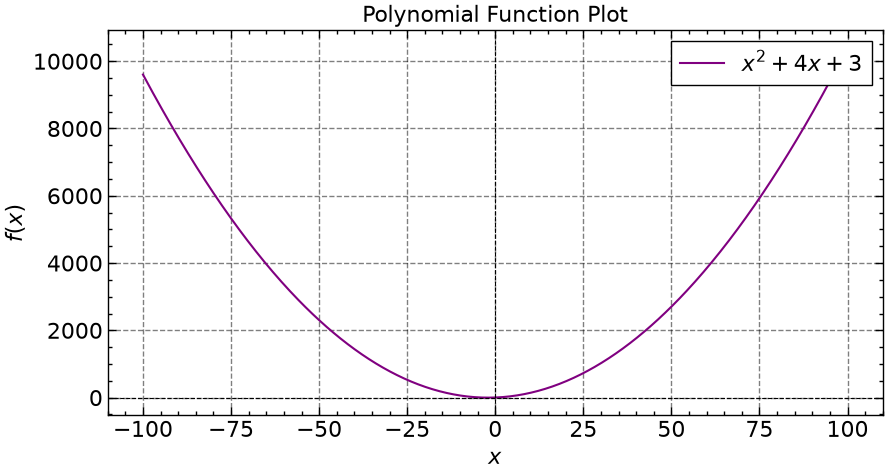

In [52]:
algebra = CollegeAlgebraCal()
algebra.run()